# BÀI THỰC HÀNH 2: MẠNG NEURAL TÍCH CHẬP

### Bài 1: Xây dựng mô hình LeNet. Huấn luyện và đánh giá mô hình LeNet trên 4 độ đo precision, recall và F1-macro (sử dụng Adam làm optimizer).

In [1]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("torch :", torch.__version__)
print("device :", device)

torch : 2.11.0+cu128
device : cuda


In [2]:
import time, random, copy
from pathlib import Path
from collections import OrderedDict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from torch.utils.data import Dataset, DataLoader, Subset, random_split
from torchvision import datasets, transforms
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, classification_report, confusion_matrix)


In [3]:
def n_params(module, trainable_only=False):
    ps = module.parameters()
    if trainable_only:
        ps = (p for p in module.parameters() if p.requires_grad)
    return sum(p.numel() for p in ps)

def show(label, t):
    print(f"{label:<28} {tuple(t.shape)}")

In [4]:
import zipfile
import gdown
from pathlib import Path

ZIP_PATH = Path("VinaFood21.zip")
RAW_DIR = Path("VinaFood21")

file_id = "1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR"
gdown.download(id=file_id, output=str(ZIP_PATH), quiet=False)

if not (RAW_DIR / "train").is_dir() or not (RAW_DIR / "test").is_dir():
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(Path("."))

DATA_ROOT = RAW_DIR

print("DATA_ROOT:", DATA_ROOT.resolve())
print("Thư mục con:", sorted(p.name for p in DATA_ROOT.iterdir()))

Downloading...
From (original): https://drive.google.com/uc?id=1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR
From (redirected): https://drive.google.com/uc?id=1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR&confirm=t&uuid=dd3e6b38-02cb-41fa-86bd-e6a93479f832
To: /kaggle/working/VinaFood21.zip
100%|██████████| 2.71G/2.71G [00:22<00:00, 121MB/s]


DATA_ROOT: /kaggle/working/VinaFood21
Thư mục con: ['README.txt', 'test', 'train']


In [5]:
# Thu nhỏ ảnh một lần để đọc dữ liệu nhanh hơn
from concurrent.futures import ThreadPoolExecutor
from PIL import Image

SMALL_ROOT = Path("VinaFood21_small")
SHORT_SIDE = 256

def shrink(src):
    dst = SMALL_ROOT / src.relative_to(DATA_ROOT)
    dst = dst.with_name(dst.name + ".jpg")
    if dst.exists():
        return
    dst.parent.mkdir(parents=True, exist_ok=True)
    with Image.open(src) as im:
        im = im.convert("RGB")
        w, h = im.size
        s = SHORT_SIDE / min(w, h)
        if s < 1:
            im = im.resize((round(w * s), round(h * s)), Image.LANCZOS)
        im.save(dst, quality=95)

exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
files = [p for p in DATA_ROOT.rglob("*") if p.is_file() and p.suffix.lower() in exts]
print("số ảnh cần thu nhỏ:", len(files))
with ThreadPoolExecutor(max_workers=4) as ex:
    list(ex.map(shrink, files))

DATA_ROOT = SMALL_ROOT
print("DATA_ROOT mới:", DATA_ROOT.resolve())
print("Thư mục con:", sorted(p.name for p in DATA_ROOT.iterdir()))

số ảnh cần thu nhỏ: 16726


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


DATA_ROOT mới: /kaggle/working/VinaFood21_small
Thư mục con: ['test', 'train']


In [6]:
IMG_SIZE = 64
BATCH = 32
SEED = 42

HAS_DATA = (DATA_ROOT / "train").is_dir()
print("Tìm thấy dữ liệu:", HAS_DATA, "-", DATA_ROOT.resolve())

HAS_TV = READY = HAS_DATA
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # mean/std của ImageNet

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

Tìm thấy dữ liệu: True - /kaggle/working/VinaFood21_small


In [7]:
VAL_FRAC = 0.1

base_ds = datasets.ImageFolder(DATA_ROOT / "train")
CLASSES = base_ds.classes
n_val = int(len(base_ds) * VAL_FRAC)

train_sub, val_sub = random_split(
    base_ds, [len(base_ds) - n_val, n_val],
    generator=torch.Generator().manual_seed(42))

print("số lớp:", len(CLASSES), "| train:", len(train_sub), "| val:", len(val_sub))

số lớp: 21 | train: 9040 | val: 1004


In [8]:
def make_transforms(img_size, augment=True):
    eval_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    if augment:
        train_tf = transforms.Compose([
            transforms.RandomResizedCrop(img_size, scale=(0.7, 1.0)),
            transforms.RandomHorizontalFlip(),
            transforms.RandomRotation(15),
            transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ])
    else:
        train_tf = eval_tf
    return train_tf, eval_tf

class TransformedSubset(Dataset):
    # Bọc một Subset để gắn transform riêng cho subset đó
    def __init__(self, subset, transform):
        self.subset, self.transform = subset, transform
    def __len__(self):
        return len(self.subset)
    def __getitem__(self, i):
        img, label = self.subset[i]
        return self.transform(img), label

def build_datasets(img_size, augment=True):
    train_tf, eval_tf = make_transforms(img_size, augment)
    train_ds = TransformedSubset(train_sub, train_tf)
    val_ds = TransformedSubset(val_sub, eval_tf)
    test_ds = datasets.ImageFolder(DATA_ROOT / "test", transform=eval_tf)
    return train_ds, val_ds, test_ds, CLASSES

def make_loaders(img_size, augment=True):
    train_ds, val_ds, test_ds, classes = build_datasets(img_size, augment)
    train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2)
    val_dl = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=2)
    test_dl = DataLoader(test_ds, batch_size=BATCH, shuffle=False, num_workers=2)
    return train_dl, val_dl, test_dl, classes


In [9]:
train_dl, val_dl, test_dl, CLASSES = make_loaders(64)
print("số lớp :", len(CLASSES))
print("số ảnh train / val / test:", len(train_dl.dataset), "/", len(val_dl.dataset), "/", len(test_dl.dataset))
print("thứ tự lớp :", CLASSES[:5], "...")

anh, nhan = train_dl.dataset[0]
xb, yb = next(iter(train_dl))
show("một ảnh sau transform", anh)
show("một batch vào model", xb)
show("nhãn", yb)


số lớp : 21
số ảnh train / val / test: 9040 / 1004 / 6682
thứ tự lớp : ['banh-can', 'banh-hoi', 'banh-mi-chao', 'banh-tet', 'banh-trang-tron'] ...
một ảnh sau transform        (3, 64, 64)
một batch vào model          (32, 3, 64, 64)
nhãn                         (32,)


In [10]:
# Huấn luyện một epoch
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train() # bật dropout, BN dùng thống kê batch
    total, correct, running = 0, 0, 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)
    return running / total, correct / total

# Đánh giá, trả về cả y_true và y_pred để tính macro-F1 và confusion matrix
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval() # tắt dropout, BN dùng thống kê tích luỹ
    total, correct, running = 0, 0, 0.0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        running += criterion(logits, yb).item() * yb.size(0)
        pred = logits.argmax(1)
        correct += (pred == yb).sum().item()
        total += yb.size(0)
        y_true += yb.cpu().tolist()
        y_pred += pred.cpu().tolist()
    return running / total, correct / total, y_true, y_pred

In [11]:
RESULTS = {}

def run_experiment(name, model, train_dl, val_dl, test_dl, classes, epochs, lr, resize):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)

    hist = {"epoch": [], "train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "sec": []}
    best_val, best_epoch, best_state = float("inf"), 0, None
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_dl, criterion, optimizer, device)
        va_loss, va_acc, _, _ = evaluate(model, val_dl, criterion, device)
        sec = time.time() - t0
        for k, v in zip(hist, (ep, tr_loss, va_loss, tr_acc, va_acc, sec)):
            hist[k].append(v)
        print(f"epoch {ep:>2} train {tr_loss:.4f}/{tr_acc:.4f}"
              f" val {va_loss:.4f}/{va_acc:.4f}  ({sec:.1f}s)")
        if va_loss < best_val:
            best_val, best_epoch = va_loss, ep
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    _, _, y_true, y_pred = evaluate(model, test_dl, criterion, device)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    RESULTS[name] = dict(
        resize=resize, params=n_params(model), trainable=n_params(model, True),
        sec_per_epoch=float(np.mean(hist["sec"])), best_epoch=best_epoch,
        acc=float(accuracy_score(y_true, y_pred)), precision=float(p), recall=float(r), macro_f1=float(f1),
        y_true=y_true, y_pred=y_pred, classes=list(classes), history=hist)
    print(f"\n    {name}: test acc {RESULTS[name]['acc']:.4f} | macro-F1 {RESULTS[name]['macro_f1']:.4f} "
          f"| epoch tốt nhất (val loss) = {best_epoch}")
    return model

In [12]:
def show_result(name):
    r = RESULTS[name]
    print(f"=== {name} | resize {r['resize']} | {r['params']:,} tham số | {r['sec_per_epoch']:.1f} giây/epoch ===")
    display(pd.DataFrame({"Accuracy": [r["acc"]], "Precision (macro)": [r["precision"]],
                          "Recall (macro)": [r["recall"]], "F1 (macro)": [r["macro_f1"]]},
                         index=["test"]).round(4))

    labels = list(range(len(r["classes"])))
    print(classification_report(r["y_true"], r["y_pred"], labels=labels,
                                target_names=r["classes"], digits=4, zero_division=0))

    h = r["history"]
    plt.figure(figsize=(6, 4))
    plt.plot(h["epoch"], h["train_loss"], label="train loss")
    plt.plot(h["epoch"], h["val_loss"], label="val loss")
    plt.axvline(r["best_epoch"], ls="--", c="gray", label=f"val loss thấp nhất (epoch {r['best_epoch']})")
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.title(name); plt.legend(); plt.show()

    cm = confusion_matrix(r["y_true"], r["y_pred"], labels=labels)
    plt.figure(figsize=(13, 11))
    sns.heatmap(cm, xticklabels=r["classes"], yticklabels=r["classes"],
                cmap="Blues", annot=True, fmt="d", annot_kws={"size": 6}, cbar=False)
    plt.xlabel("dự đoán"); plt.ylabel("nhãn thật"); plt.title(f"Confusion matrix - {name}")
    plt.show()

def summary_table(names):
    rows = []
    for n in names:
        r = RESULTS[n]
        rows.append({"Mô hình": n, "Resize": r["resize"], "Tham số": f"{r['params']:,}",
                     "Tham số được học": f"{r['trainable']:,}", "Giây/epoch": round(r["sec_per_epoch"], 1),
                     "Accuracy": round(r["acc"], 4), "macro-F1": round(r["macro_f1"], 4)})
    return pd.DataFrame(rows)

In [13]:
# Định nghĩa LeNet-5 với số channel vào, kích thước ảnh và số lớp tham số hoá
class LeNet5(nn.Module):
    def __init__(self, in_ch=3, img=64, num_classes=21, pool="avg"):
        super().__init__()
        Pool = nn.AvgPool2d if pool == "avg" else nn.MaxPool2d
        self.c1 = nn.Conv2d(in_ch, 6, kernel_size=5)
        self.s2 = Pool(2, 2)
        self.c3 = nn.Conv2d(6, 16, kernel_size=5)
        self.s4 = Pool(2, 2)

        n_flat = self._flat_dim(in_ch, img)
        self.f5 = nn.Linear(n_flat, 120)
        self.f6 = nn.Linear(120, 84)
        self.out = nn.Linear(84, num_classes)
        self.n_flat = n_flat

    def _flat_dim(self, in_ch, img):
        # Dò số chiều sau S4 bằng một forward giả, tránh tính tay
        with torch.no_grad():
            z = torch.zeros(1, in_ch, img, img)
            z = self.s4(self.c3(self.s2(self.c1(z))))
        return int(z.flatten(1).shape[1])

    def forward(self, x):
        x = self.s2(torch.relu(self.c1(x)))
        x = self.s4(torch.relu(self.c3(x)))
        x = x.flatten(1)
        x = torch.relu(self.f5(x))
        x = torch.relu(self.f6(x))
        return self.out(x)


In [14]:
# Khởi tạo cấu hình của Bài 1: ảnh 64x64x3, 21 lớp
lenet = LeNet5(in_ch=3, img=64, num_classes=21)
print("số chiều sau flatten:", lenet.n_flat)
print("tổng tham số        :", f"{n_params(lenet):,}")

assert lenet.n_flat == 2704
assert n_params(lenet) == 339_421

số chiều sau flatten: 2704
tổng tham số        : 339,421


In [15]:
# Hàm dựng bảng shape và tham số của từng layer
def layer_table(model, img, in_ch=3):
    x = torch.zeros(1, in_ch, img, img)
    rows, total = [], 0
    for name, layer in [("C1", model.c1), ("S2", model.s2),
                        ("C3", model.c3), ("S4", model.s4)]:
        x = layer(x)
        p = n_params(layer)
        total += p
        rows.append((name, "x".join(map(str, tuple(x.shape)[1:])), p))
    x = x.flatten(1)
    rows.append(("flatten", str(x.shape[1]), 0))
    for name, layer in [("F5", model.f5), ("F6", model.f6), ("OUT", model.out)]:
        x = layer(x)
        p = n_params(layer)
        total += p
        rows.append((name, str(x.shape[1]), p))
    return rows, total

# In bảng cho cấu hình ảnh 64x64
rows, total = layer_table(lenet, 64)

print(f"\n{'layer':<10}{'output':<16}{'tham số':>12}")
for name, shape, p in rows:
    print(f"{name:<10}{shape:<16}{p:>12,}")
print(f"{'TỔNG':<10}{'':<16}{total:>12,}")
assert total == 339_421


layer     output               tham số
C1        6x60x60                  456
S2        6x30x30                    0
C3        16x26x26               2,416
S4        16x13x13                   0
flatten   2704                       0
F5        120                  324,600
F6        84                    10,164
OUT       21                     1,785
TỔNG                           339,421


In [16]:
# Huấn luyện LeNet-5 AvgPool. Adam lr=1e-3, 20 epoch
EPOCHS_LENET = 20
set_seed()
lenet_avg = LeNet5(in_ch=3, img=64, num_classes=len(CLASSES), pool="avg")
run_experiment("LeNet-5 (AvgPool)", lenet_avg, train_dl, val_dl, test_dl, CLASSES,
               epochs=EPOCHS_LENET, lr=1e-3, resize="64x64")

epoch  1 train 2.7928/0.1583 val 2.6461/0.2102  (14.7s)
epoch  2 train 2.5961/0.2084 val 2.5262/0.2251  (13.5s)
epoch  3 train 2.4929/0.2362 val 2.4337/0.2550  (13.6s)
epoch  4 train 2.4133/0.2610 val 2.4431/0.2490  (13.5s)
epoch  5 train 2.3481/0.2783 val 2.3353/0.2799  (13.5s)
epoch  6 train 2.2968/0.2898 val 2.3210/0.2978  (13.4s)
epoch  7 train 2.2522/0.3050 val 2.3641/0.2679  (13.6s)
epoch  8 train 2.2005/0.3217 val 2.2883/0.2769  (13.3s)
epoch  9 train 2.1640/0.3416 val 2.2975/0.2908  (13.4s)
epoch 10 train 2.1154/0.3497 val 2.2113/0.3177  (13.4s)
epoch 11 train 2.0932/0.3583 val 2.2062/0.3217  (13.5s)
epoch 12 train 2.0341/0.3782 val 2.1753/0.3317  (13.5s)
epoch 13 train 2.0228/0.3802 val 2.1543/0.3486  (13.7s)
epoch 14 train 1.9967/0.3780 val 2.1611/0.3426  (13.7s)
epoch 15 train 1.9803/0.3927 val 2.1681/0.3267  (13.7s)
epoch 16 train 1.9405/0.4044 val 2.1314/0.3616  (13.7s)
epoch 17 train 1.9174/0.4091 val 2.1811/0.3376  (13.9s)
epoch 18 train 1.9011/0.4149 val 2.1140/0.3546  

LeNet5(
  (c1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (s2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (c3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (s4): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (f5): Linear(in_features=2704, out_features=120, bias=True)
  (f6): Linear(in_features=120, out_features=84, bias=True)
  (out): Linear(in_features=84, out_features=21, bias=True)
)

=== LeNet-5 (AvgPool) | resize 64x64 | 339,421 tham số | 13.6 giây/epoch ===


,Accuracy,Precision (macro),Recall (macro),F1 (macro)
test,0.3201,0.3085,0.3035,0.2921


                  precision    recall  f1-score   support

        banh-can     0.2443    0.1328    0.1720       241
        banh-hoi     0.3723    0.4201    0.3947       607
    banh-mi-chao     0.3213    0.4014    0.3569       289
        banh-tet     0.3475    0.2253    0.2733       364
 banh-trang-tron     0.1429    0.0680    0.0921       309
          banh-u     0.3452    0.1648    0.2231       176
        banh-uot     0.2984    0.2589    0.2772       560
       bap-nuong     0.2083    0.0699    0.1047       143
          bo-kho     0.2989    0.4024    0.3430       338
       bo-la-lot     0.4344    0.5786    0.4963       458
       bot-chien     0.2300    0.3551    0.2792       276
           ca-ri     0.2791    0.0702    0.1121       171
    canh-kho-qua     0.4208    0.6414    0.5082       290
   canh-khoai-mo     0.6558    0.7121    0.6828       198
        ga-nuong     0.3223    0.2366    0.2729       372
          goi-ga     0.2879    0.1966    0.2336       290
          ha-

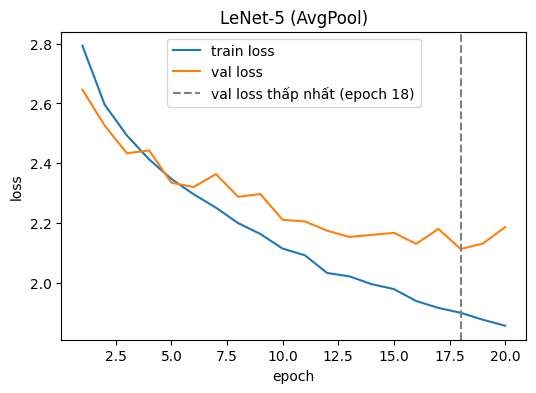

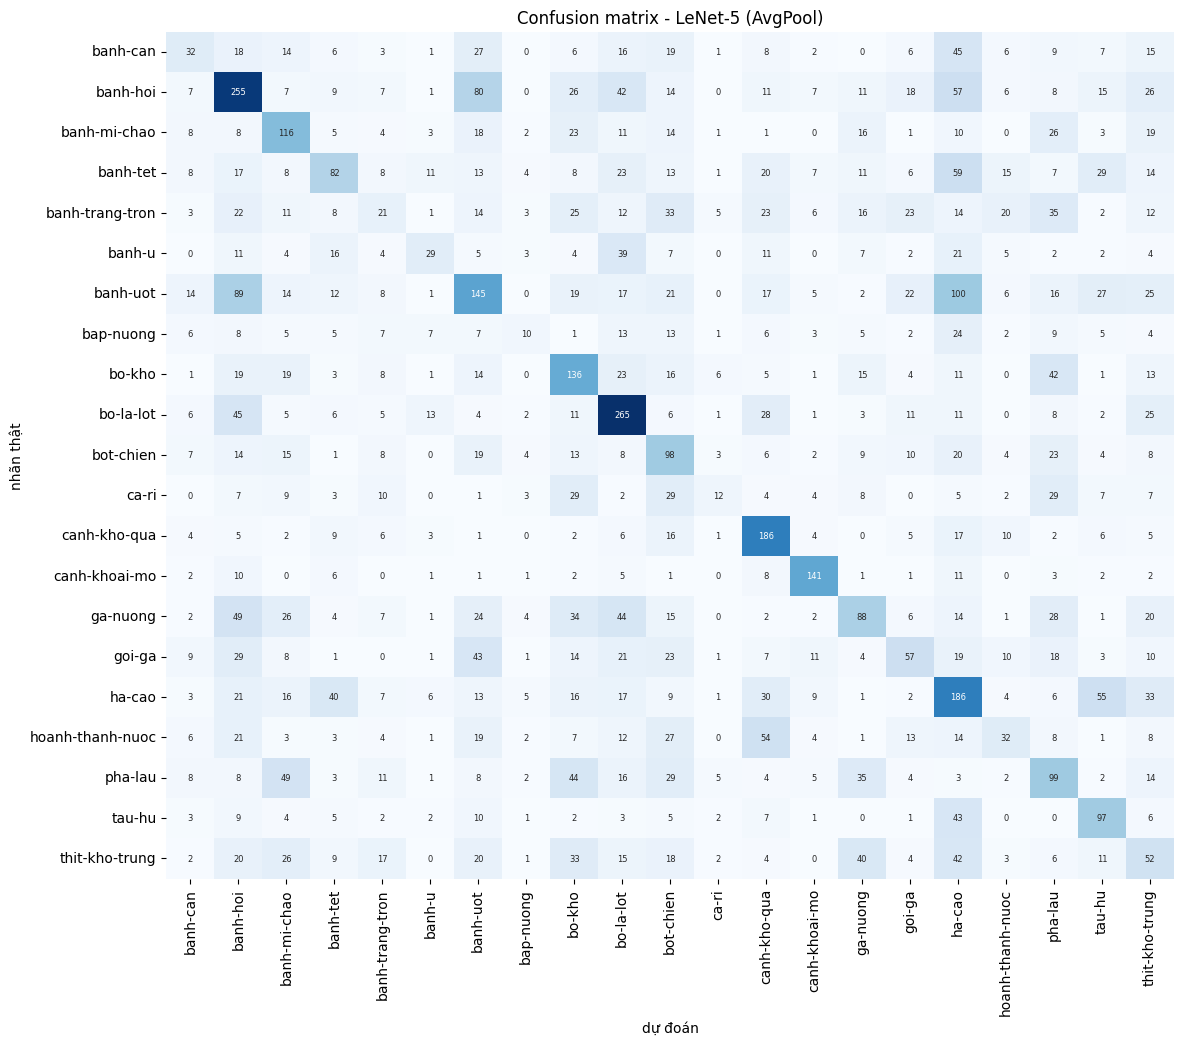

In [17]:
show_result("LeNet-5 (AvgPool)")

In [18]:
# Thay AvgPool2d(2, 2) bằng MaxPool2d(2, 2) và chạy lại
set_seed()
lenet_max = LeNet5(in_ch=3, img=64, num_classes=len(CLASSES), pool="max")
assert n_params(lenet_max) == n_params(lenet_avg)    # pooling không có tham số
run_experiment("LeNet-5 (MaxPool)", lenet_max, train_dl, val_dl, test_dl, CLASSES,
               epochs=EPOCHS_LENET, lr=1e-3, resize="64x64")

epoch  1 train 2.8019/0.1554 val 2.6330/0.2181  (13.6s)
epoch  2 train 2.5603/0.2154 val 2.4756/0.2341  (13.6s)
epoch  3 train 2.4570/0.2471 val 2.4574/0.2480  (13.5s)
epoch  4 train 2.3707/0.2746 val 2.4180/0.2380  (13.7s)
epoch  5 train 2.2960/0.2908 val 2.3145/0.2849  (13.6s)
epoch  6 train 2.2375/0.3116 val 2.2724/0.2988  (13.8s)
epoch  7 train 2.1838/0.3192 val 2.2908/0.3028  (13.5s)
epoch  8 train 2.1345/0.3462 val 2.2621/0.3147  (13.6s)
epoch  9 train 2.1018/0.3499 val 2.1868/0.3456  (13.8s)
epoch 10 train 2.0560/0.3627 val 2.1593/0.3317  (13.6s)
epoch 11 train 2.0292/0.3739 val 2.1488/0.3456  (13.8s)
epoch 12 train 2.0004/0.3897 val 2.1533/0.3317  (13.6s)
epoch 13 train 1.9784/0.3896 val 2.1165/0.3546  (13.9s)
epoch 14 train 1.9369/0.3952 val 2.1275/0.3337  (13.7s)
epoch 15 train 1.9352/0.4000 val 2.1217/0.3376  (13.7s)
epoch 16 train 1.8935/0.4104 val 2.0655/0.3685  (13.6s)
epoch 17 train 1.8733/0.4167 val 2.1458/0.3576  (13.8s)
epoch 18 train 1.8498/0.4262 val 2.1106/0.3536  

LeNet5(
  (c1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (s2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (c3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (s4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (f5): Linear(in_features=2704, out_features=120, bias=True)
  (f6): Linear(in_features=120, out_features=84, bias=True)
  (out): Linear(in_features=84, out_features=21, bias=True)
)

=== LeNet-5 (MaxPool) | resize 64x64 | 339,421 tham số | 13.7 giây/epoch ===


,Accuracy,Precision (macro),Recall (macro),F1 (macro)
test,0.3182,0.3102,0.302,0.2933


                  precision    recall  f1-score   support

        banh-can     0.2320    0.1203    0.1585       241
        banh-hoi     0.3501    0.5041    0.4132       607
    banh-mi-chao     0.3013    0.2388    0.2664       289
        banh-tet     0.4923    0.2637    0.3435       364
 banh-trang-tron     0.1841    0.1197    0.1451       309
          banh-u     0.1471    0.0568    0.0820       176
        banh-uot     0.3008    0.3357    0.3173       560
       bap-nuong     0.2314    0.1958    0.2121       143
          bo-kho     0.2773    0.2781    0.2777       338
       bo-la-lot     0.4504    0.5546    0.4971       458
       bot-chien     0.2837    0.2138    0.2438       276
           ca-ri     0.2453    0.0760    0.1161       171
    canh-kho-qua     0.4579    0.4690    0.4634       290
   canh-khoai-mo     0.7053    0.7374    0.7210       198
        ga-nuong     0.2990    0.1640    0.2118       372
          goi-ga     0.3099    0.1828    0.2299       290
          ha-

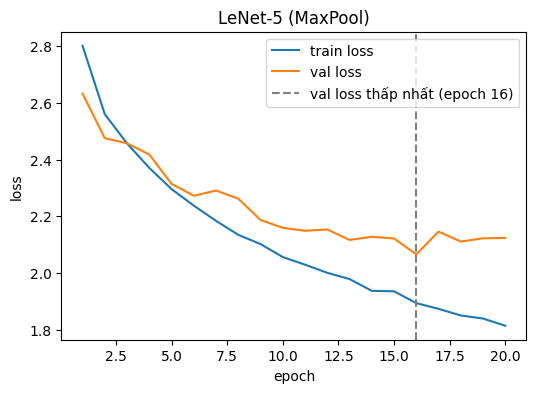

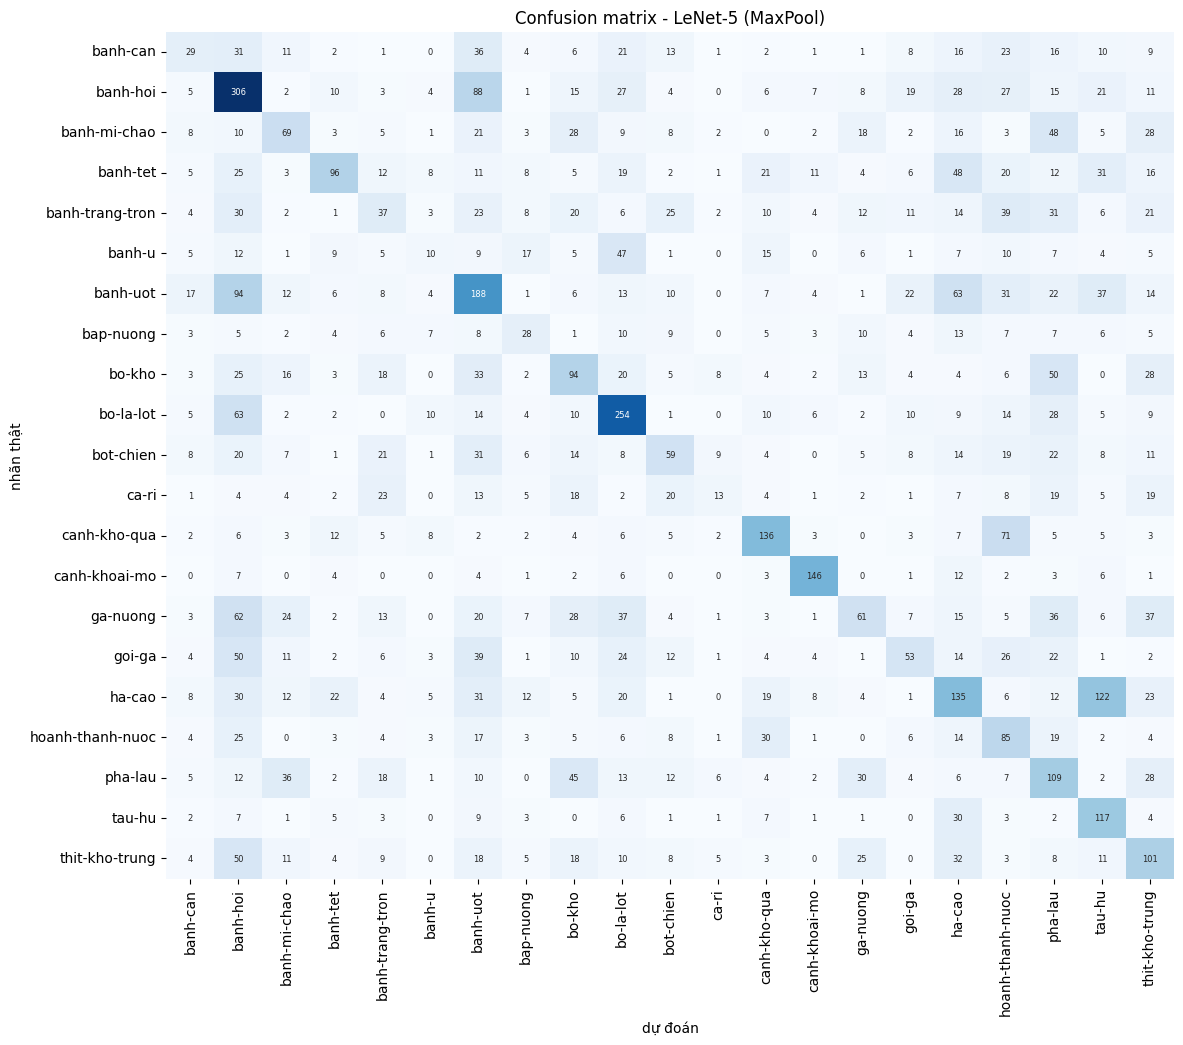

In [19]:
show_result("LeNet-5 (MaxPool)")

In [20]:
cmp = pd.DataFrame({n: {"Tham số": f"{RESULTS[n]['params']:,}", "Giây/epoch": round(RESULTS[n]["sec_per_epoch"], 1),
                        "Accuracy": RESULTS[n]["acc"], "Precision (macro)": RESULTS[n]["precision"],
                        "Recall (macro)": RESULTS[n]["recall"], "F1 (macro)": RESULTS[n]["macro_f1"]}
                    for n in ["LeNet-5 (AvgPool)", "LeNet-5 (MaxPool)"]}).T
print(cmp)

                   Tham số Giây/epoch  Accuracy Precision (macro)  \
LeNet-5 (AvgPool)  339,421       13.6  0.320114          0.308518   
LeNet-5 (MaxPool)  339,421       13.7  0.318168          0.310165   

                  Recall (macro) F1 (macro)  
LeNet-5 (AvgPool)       0.303518   0.292114  
LeNet-5 (MaxPool)       0.302037   0.293304  


### Bài 2: Xây dựng mô hình GoogLeNet. Huấn luyện và đánh giá mô hình GoogLeNet trên 4 độ đo precision, recall và F1 (sử dụng Adam làm optimizer).

In [21]:
# Inception block
class InceptionBlock(nn.Module):
    def __init__(self, in_ch, f1, f3r, f3, f5r, f5, fp):
        super().__init__()
        self.b1 = nn.Sequential(
            nn.Conv2d(in_ch, f1, 1), nn.ReLU())
        self.b2 = nn.Sequential(
            nn.Conv2d(in_ch, f3r, 1), nn.ReLU(),
            nn.Conv2d(f3r, f3, 3, padding=1), nn.ReLU())
        self.b3 = nn.Sequential(
            nn.Conv2d(in_ch, f5r, 1), nn.ReLU(),
            nn.Conv2d(f5r, f5, 5, padding=2), nn.ReLU())
        self.b4 = nn.Sequential(
            nn.MaxPool2d(3, stride=1, padding=1),
            nn.Conv2d(in_ch, fp, 1), nn.ReLU())

    def forward(self, x):
        # dim=1 là chiều channel
        return torch.cat([self.b1(x), self.b2(x),
                          self.b3(x), self.b4(x)], dim=1)

In [22]:
blk1 = InceptionBlock(1, 16, 16, 24, 4, 8, 8)
x1 = torch.rand(1, 1, 28, 28)
print("shape ra của từng nhánh:")
for name, br in [("1x1", blk1.b1), ("1x1->3x3", blk1.b2), ("1x1->5x5", blk1.b3), ("pool->1x1", blk1.b4)]:
    show("  " + name, br(x1))
show("sau concat", blk1(x1))
print("block (1, 16, 16, 24, 4, 8, 8)     :", blk1(x1).shape[1], "channel,", f"{n_params(blk1):,}", "tham số")

blk2 = InceptionBlock(56, 32, 32, 48, 8, 16, 16)
y2 = blk2(torch.rand(1, 56, 14, 14))
print("block (56, 32, 32, 48, 8, 16, 16)  :", y2.shape[1], "channel,", f"{n_params(blk2):,}", "tham số")

shape ra của từng nhánh:
  1x1                        (1, 16, 28, 28)
  1x1->3x3                   (1, 24, 28, 28)
  1x1->5x5                   (1, 8, 28, 28)
  pool->1x1                  (1, 8, 28, 28)
sau concat                   (1, 56, 28, 28)
block (1, 16, 16, 24, 4, 8, 8)     : 56 channel, 4,376 tham số
block (56, 32, 32, 48, 8, 16, 16)  : 112 channel, 22,104 tham số


In [23]:
class GoogLeNetMini(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()
        self.features = nn.Sequential(OrderedDict([
            ("stem",  nn.Sequential(nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2))),  # 64 -> 32
            ("inc1",  InceptionBlock(32, 16, 16, 24, 4, 8, 8)),        # ra 56
            ("inc2",  InceptionBlock(56, 32, 32, 48, 8, 16, 16)),      # ra 112
            ("pool1", nn.MaxPool2d(2, 2)),                              # 32 -> 16
            ("inc3",  InceptionBlock(112, 48, 48, 64, 8, 16, 16)),     # ra 144
            ("inc4",  InceptionBlock(144, 64, 64, 96, 12, 32, 32)),    # ra 224
        ]))
        self.gap = nn.AdaptiveAvgPool2d(1)        # thay cho nn.Flatten() trước lớp phân loại
        self.fc = nn.Linear(224, num_classes)     # 224 = channel ra của inc4

    def forward(self, x):
        x = self.features(x)
        return self.fc(self.gap(x).flatten(1))

In [24]:
def print_shapes(model, x):
    model.eval()
    with torch.no_grad():
        print(f"{'layer':<8}{'output shape':<22}{'tham số':>10}")
        print(f"{'input':<8}{str(tuple(x.shape)):<22}")
        for name, layer in model.features.named_children():
            x = layer(x)
            print(f"{name:<8}{str(tuple(x.shape)):<22}{n_params(layer):>10,}")
        x = model.gap(x)
        print(f"{'gap':<8}{str(tuple(x.shape)):<22}{0:>10,}")
        x = model.fc(x.flatten(1))
        print(f"{'fc':<8}{str(tuple(x.shape)):<22}{n_params(model.fc):>10,}")

googlenet_check = GoogLeNetMini(num_classes=len(CLASSES))
print_shapes(googlenet_check, torch.zeros(1, 3, 64, 64))
print("TỔNG tham số:", f"{n_params(googlenet_check):,}")

# Channel ra của từng Inception block: tính tay (f1 + f3 + f5 + fp) so với in từ code
hand = {"inc1": 16 + 24 + 8 + 8, "inc2": 32 + 48 + 16 + 16, "inc3": 48 + 64 + 16 + 16, "inc4": 64 + 96 + 32 + 32}
z = googlenet_check.features.stem(torch.zeros(1, 3, 64, 64))
print(f"\n{'block':<8}{'tính tay':>10}{'từ code':>10}")
for name, expect in hand.items():
    z = getattr(googlenet_check.features, name)(z)
    if name == "inc2":
        z = googlenet_check.features.pool1(z)
    print(f"{name:<8}{expect:>10}{z.shape[1]:>10}")
    assert z.shape[1] == expect
del googlenet_check

layer   output shape             tham số
input   (1, 3, 64, 64)        
stem    (1, 32, 32, 32)              896
inc1    (1, 56, 32, 32)            5,740
inc2    (1, 112, 32, 32)          22,104
pool1   (1, 112, 16, 16)               0
inc3    (1, 144, 16, 16)          44,488
inc4    (1, 224, 16, 16)          89,964
gap     (1, 224, 1, 1)                 0
fc      (1, 21)                    4,725
TỔNG tham số: 167,917

block     tính tay   từ code
inc1            56        56
inc2           112       112
inc3           144       144
inc4           224       224


In [25]:
# Huấn luyện GoogLeNet rút gọn
set_seed()
googlenet = GoogLeNetMini(num_classes=len(CLASSES))
run_experiment("GoogLeNet rút gọn", googlenet, train_dl, val_dl, test_dl, CLASSES,
               epochs=EPOCHS_LENET, lr=1e-3, resize="64x64")

epoch  1 train 2.9079/0.1149 val 2.7616/0.1504  (14.9s)
epoch  2 train 2.6607/0.1738 val 2.5983/0.1912  (14.6s)
epoch  3 train 2.5418/0.2101 val 2.5371/0.2301  (14.4s)
epoch  4 train 2.4470/0.2352 val 2.4576/0.2390  (14.4s)
epoch  5 train 2.3605/0.2614 val 2.4454/0.2470  (14.5s)
epoch  6 train 2.2742/0.2906 val 2.2906/0.2849  (14.2s)
epoch  7 train 2.2109/0.3062 val 2.3218/0.2938  (14.2s)
epoch  8 train 2.1808/0.3201 val 2.2119/0.3287  (14.1s)
epoch  9 train 2.1139/0.3410 val 2.1311/0.3197  (14.3s)
epoch 10 train 2.0656/0.3605 val 2.1019/0.3576  (14.2s)
epoch 11 train 2.0164/0.3704 val 2.0131/0.3855  (14.3s)
epoch 12 train 1.9777/0.3873 val 2.0149/0.3695  (14.4s)
epoch 13 train 1.9348/0.3918 val 1.9101/0.3974  (14.1s)
epoch 14 train 1.8830/0.4121 val 1.9297/0.4114  (14.4s)
epoch 15 train 1.8627/0.4173 val 1.8850/0.4233  (14.4s)
epoch 16 train 1.8206/0.4295 val 1.9557/0.4243  (14.4s)
epoch 17 train 1.7913/0.4364 val 1.8864/0.4193  (14.3s)
epoch 18 train 1.7698/0.4424 val 1.8057/0.4522  

GoogLeNetMini(
  (features): Sequential(
    (stem): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (inc1): InceptionBlock(
      (b1): Sequential(
        (0): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1))
        (1): ReLU()
      )
      (b2): Sequential(
        (0): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1))
        (1): ReLU()
        (2): Conv2d(16, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (3): ReLU()
      )
      (b3): Sequential(
        (0): Conv2d(32, 4, kernel_size=(1, 1), stride=(1, 1))
        (1): ReLU()
        (2): Conv2d(4, 8, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
        (3): ReLU()
      )
      (b4): Sequential(
        (0): MaxPool2d(kernel_size=3, stride=1, padding=1, dilation=1, ceil_mode=False)
        (1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
       

=== GoogLeNet rút gọn | resize 64x64 | 167,917 tham số | 14.4 giây/epoch ===


,Accuracy,Precision (macro),Recall (macro),F1 (macro)
test,0.3839,0.4118,0.3664,0.364


                  precision    recall  f1-score   support

        banh-can     0.2362    0.3029    0.2655       241
        banh-hoi     0.5908    0.5305    0.5590       607
    banh-mi-chao     0.2245    0.7093    0.3411       289
        banh-tet     0.3853    0.5027    0.4362       364
 banh-trang-tron     0.3116    0.2168    0.2557       309
          banh-u     0.3763    0.1989    0.2602       176
        banh-uot     0.4667    0.2500    0.3256       560
       bap-nuong     0.4211    0.0559    0.0988       143
          bo-kho     0.4298    0.4349    0.4324       338
       bo-la-lot     0.6749    0.5983    0.6343       458
       bot-chien     0.3451    0.1775    0.2344       276
           ca-ri     0.3059    0.1520    0.2031       171
    canh-kho-qua     0.5951    0.5069    0.5475       290
   canh-khoai-mo     0.8393    0.7121    0.7705       198
        ga-nuong     0.3858    0.2634    0.3131       372
          goi-ga     0.3915    0.2862    0.3307       290
          ha-

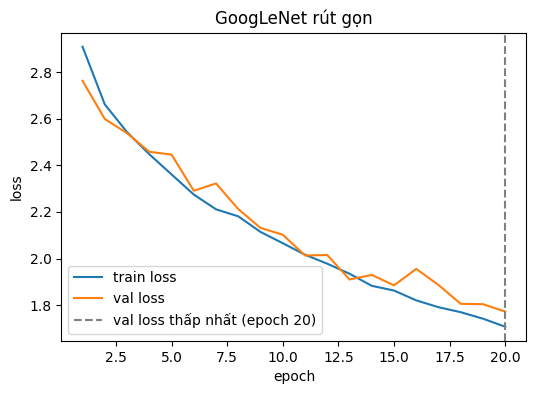

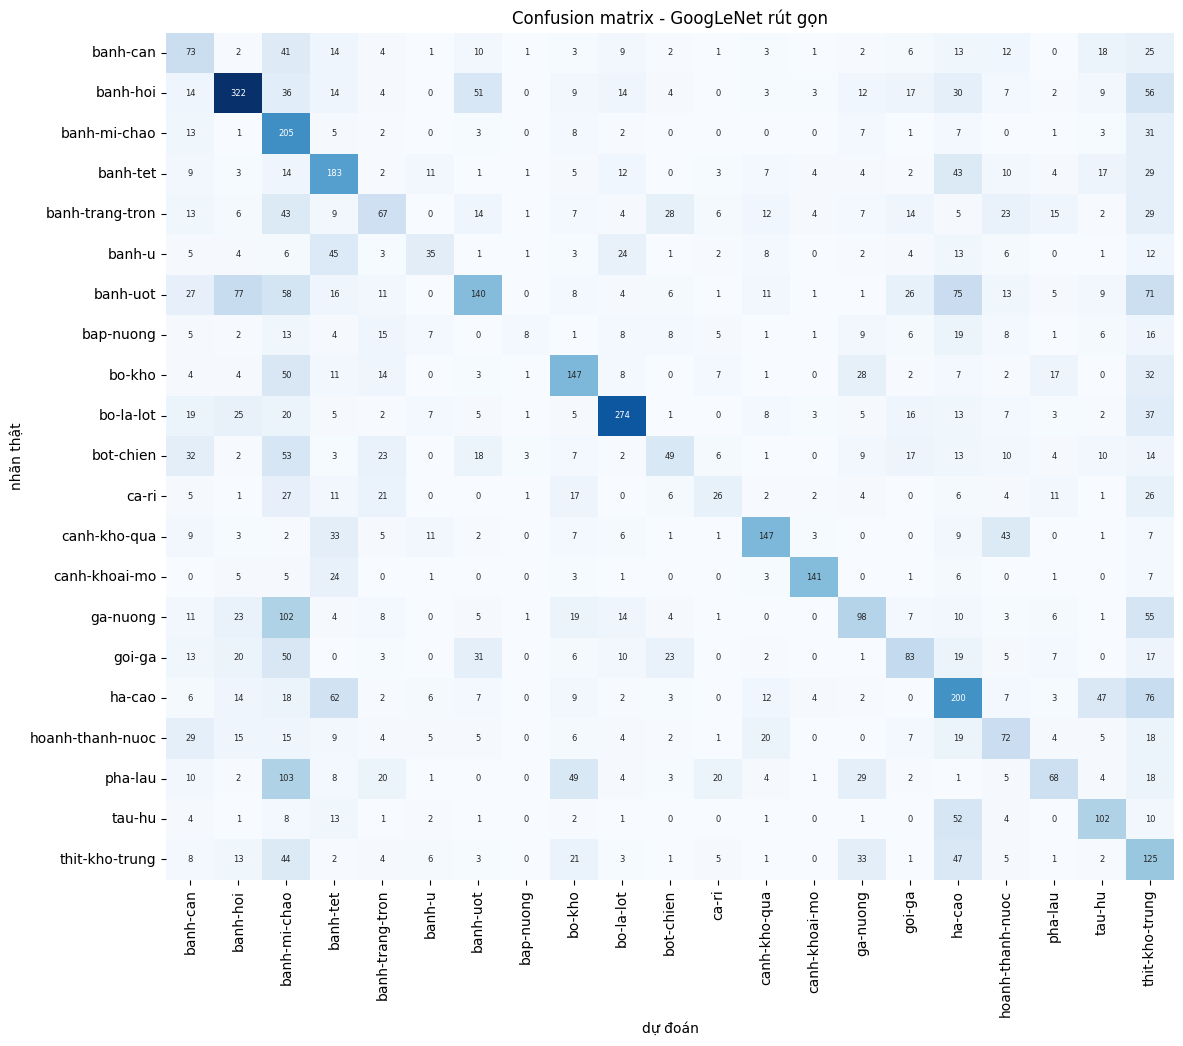

In [26]:
show_result("GoogLeNet rút gọn")

| Mô hình | Tham số | Giây/epoch | Accuracy | Precision | Recall | macro-F1 |
|---|---|---|---|---|---|---|
| LeNet-5 AvgPool | 339,421 | 13.6 | 0.3201 | 0.3085 | 0.3035 | 0.2921 |
| LeNet-5 MaxPool | 339,421 | 13.7 | 0.3182 | 0.3102 | 0.3020 | 0.2933 |
| GoogLeNet rút gọn | 167,917 | 14.4 | 0.3839 | 0.4118 | 0.3664 | 0.3640 |

- LeNet-5 AvgPool và MaxPool: tương đương
- Thời gian/epoch gần bằng nhau (13.6, 13.7, 14.4). Phần lớn thời gian là đọc và augment ảnh bằng CPU, nên con số này không phản ánh chi phí tính toán thật của model.
- Đường loss:
   - LeNet: val loss chạm đáy ở epoch 18 (Avg) và 16 (Max), rồi nhích lên: overfitting nhẹ.
   - GoogLeNet: val loss vẫn giảm đến epoch 20 nên chưa hội tụ, còn khả năng tốt hơn nếu thêm epoch.
- Nhãn được phân loại tốt nhất là canh-khoai-mo

GoogLeNet có ít tham số hơn nhưng điểm số cao hơn và vẫn chưa thể hiện hết khả năng